In [1]:
import os
os.environ["OMP_NUM_THREADS"] = "1" 
print(os.cpu_count())

144


In [2]:
import numpy as np
import math
import random as rand
import statistics
import matplotlib.pyplot as plt
from tqdm import tqdm

from sklearn.svm import SVC
from sklearn.metrics import accuracy_score

# Grid search with cross validation

From `num` data points (which is the dimension of `y`), `num_train` training data points and `num_test` testing data points are randomly selected.

Then, cross-validation is performed on the training data to determine the optimal hyperparameters. `kfold` specifies the number of folds for cross-validation, and `ite` specifies the number of repetitions for cross-validation.

The hyperparameters to be optimized are the regularization parameter (candidate values are stored in `alpha_list`) and the kernel's own hyperparameters (a list of Gram matrices with different hyperparameters is stored in `G0_list`).

Afterward, the training data is used to train the model with the optimal hyperparameters, and the prediction accuracy is output for the test data. This entire procedure is repeated `rep` times, and the mean and standard deviation of the accuracy are output.

- `num_train`: Number of training data points.
- `num_test`: Number of testing data points.
- `G0_list`: A list of Gram matrices. Each element corresponds to a Gram matrix with different hyperparameters. The optimal one will be selected from this list.
- `y`: Label vector.
- `kfold`: Number of folds for cross-validation.
- `ite`: Number of repetitions for cross-validation.
- `rep`: Number of repetitions for the entire procedure.
- `seed`: Random seed.
- `alpha_list`: List of regularization parameter candidates.

In [4]:
def calculate_pred_acc(num_train, num_test, G0_list, y, kfold, ite, rep, seed, alpha_list):
    rand.seed(seed)
    num = len(y)
    
    fin_acc_list = []
    # The calculation of accuracy is repeated `rep` times, varying the training and test data each time, to determine the average accuracy.
    for _ in range(rep):   
        a = [i for i in range(num)]
        rand.shuffle(a)
        train_list = sorted(a[0:num_train], key=abs)
        test_list = sorted(a[num_train:num_train+num_test], key=abs)

        ## Determine optimal alpha and hyperparameters
        G0,alpha = optimize_hyperparameters(train_list, test_list, G0_list, y, kfold, ite, alpha_list)
        
        ## Perform SVM with oprimal G0 to calculate accuracy
        G_train, G_test, y_train, y_test = divide_data(G0, y, train_list, test_list)
        svm = SVC(kernel="precomputed", C=alpha)
        svm.fit(G_train, y_train)
        ptest = svm.predict(G_test)
        fin_acc = accuracy_score(y_test, ptest)
        fin_acc_list.append(fin_acc)
    
    # Calculate mean and standard dev over rep results
    if rep==1:
        mean = fin_acc_list[0]
        stdv = 0.0
    else:
        mean = statistics.mean(fin_acc_list)
        stdv = statistics.stdev(fin_acc_list)
        
    #print(f"fin_acc_list = {fin_acc_list}")
    print(f"num_train = {num_train}: mean = {mean}, stdv = {stdv}")
    print(f"----------------------------")
    
    return mean, stdv

Perform grid search on the training data `train_list` using cross-validation to optimize hyperparameters.

- `train_list`: List of training data.
- `test_list`: List of testing data.
- `G0_list`: List of Gram matrices.
- `y`: Label vector.
- `kfold`: Number of splits for cross-validation.
- `ite`: Number of repetitions for cross-validation.
- `alpha_list`: List of candidate regularization parameters.

In [5]:
def optimize_hyperparameters(train_list, test_list, G0_list, y, kfold, ite, alpha_list):
    ## Determine optimal alpha and hyperparameters
    alpha_cand = []
    acc_cand = []
    ### Optimize alpha for each G0
    for G0 in G0_list:
        # From `num` data points, `num_train` training data points and `num_test` testing data points are extracted.
        G_train, G_test, y_train, y_test = divide_data(G0, y, train_list, test_list)
        alpha, acc = grid_search_SVM(kfold, ite, G_train, y_train, alpha_list)
        alpha_cand.append(alpha)
        acc_cand.append(acc)

    ### Find optimal G0
    index = np.argmax(acc_cand)
    alpha = alpha_cand[index]
    G0 = G0_list[index]
    
    return G0, alpha

Extract sub-matrices of the Gram matrix `G0` and label vector `y` corresponding to the training data `train_list` and test data `test_list`.

- `G0`: Gram matrix.
- `y`: Label vector.
- `train_list`: List of training data indices.
- `test_list`: List of testing data indices.

In [6]:
def divide_data(G0, y, train_list, test_list):
    
    G_train = np.take(G0, train_list, axis=0)
    G_train = np.take(G_train, train_list, axis=1)
    
    G_test = np.take(G0, test_list, axis=0)
    G_test = np.take(G_test, train_list, axis=1)
    
    y_train = np.take(y, train_list, axis=0)
    y_test = np.take(y, test_list, axis=0)
    
    return G_train, G_test, y_train, y_test

Perform a grid search for the regularization parameter `alpha` from `alpha_list`.

For each `alpha` value, `k-fold` cross-validation (where `k=kfold`) is repeated `ite` times on the training Gram matrix (`G_train`) and training label vector (`y_train`). The optimal `alpha` is determined based on the average results from these repetitions.

- `kfold`: Number of folds for cross-validation.
- `ite`: Number of repetitions for cross-validation.
- `G_train`: Gram matrix of the training data.
- `y_train`: Label vector of the training data.
- `alpha_list`: List of candidate regularization parameters.

In [7]:
def grid_search_SVM(kfold, ite, G_train, y_train, alpha_list):
    
    acc_list = []
    for alpha in alpha_list:
        acc = cross_validation(kfold, ite, G_train, y_train, alpha)
        acc_list.append(acc)
        #print(f"alpha = {alpha}, mse = {mse}")
        #print(f"------------------------------------")
        
    index = np.argmax(acc_list)
    print(f"Best alpha = {alpha_list[index]}, acc = {acc_list[index]}")
    
    return alpha_list[index], acc_list[index]

**Cross-validation**

For a given regularization parameter `alpha`, `k-fold` cross-validation (where `k=kfold`) is performed `ite` times using the training Gram matrix (`G_train`) and training label vector (`y_train`). The average accuracy from these repetitions is then calculated.

- `kfold`: Number of folds for cross-validation.
- `ite`: Number of repetitions for cross-validation.
- `G_train`: Gram matrix of the training data.
- `y_train`: Label vector of the training data.
- `alpha`: Regularization parameter.

In [8]:
def cross_validation(kfold, ite, G_train, y_train, alpha):
    
    num_data = len(y_train)
    index_list = [i for i in range(num_data)]
    
    acc_list = []
    for _ in range(ite):
        group_list = shuffle_and_divide(num_data, kfold)  
        for i in range(kfold):
            train_data_cv = sorted([x for x in index_list if x not in group_list[i]],key=abs)
            valid_data_cv = group_list[i] 

            G_train_cv = partition_train(G_train, valid_data_cv)
            G_valid_cv = partition_valid(G_train, valid_data_cv)
            y_train_cv = [y_train[j] for j in train_data_cv]
            y_valid_cv = [y_train[j] for j in valid_data_cv]

            # Learning & prediction
            svm = SVC(kernel="precomputed", C=alpha)
            svm.fit(G_train_cv, y_train_cv)
            prediction = svm.predict(G_valid_cv)
            acc = accuracy_score(y_valid_cv, prediction)
            #print(f"i={i}: acc = {acc}")
            acc_list.append(acc)
        
    return statistics.mean(acc_list)

Divide the training Gram matrix `G_train` into validation data (`cv_valid`) and the remaining data.

- `G_train`: Gram matrix of the training data.
- `valid_data_cv`: List of validation data indices.

In [9]:
def partition_train(G_train, valid_data_cv):
    G_train_cv = np.delete(G_train, valid_data_cv, axis=0)
    G_train_cv = np.delete(G_train_cv, valid_data_cv, axis=1)
    
    return G_train_cv

def partition_valid(G_train, valid_data_cv):
    num_data = len(G_train)
    index_list = [i for i in range(num_data)]
    train_list_cv = sorted([x for x in index_list if x not in valid_data_cv],key=abs)
    
    G_valid_cv = np.delete(G_train, train_list_cv, axis=0)
    G_valid_cv = np.delete(G_valid_cv, valid_data_cv, axis=1)
    
    return G_valid_cv

**For Cross-Validation (CV) Use**

Divide numbers from 0 to `num-1` into `g` groups to create a nested list.
For example, numbers from 0 to 8 might be split into `group_list=[[3,4,7],[0,2,8],[2,4,5]]`. The inner lists should be sorted.

In [10]:
# Random splitting
def shuffle_and_divide(num, g):
    quot = num//g 
    extra = num%g

    a = [i for i in range(num)]
    rand.shuffle(a)
    group_list = []
    ini = 0
    for i in range(g):
        if i<extra:
            b = a[ini:ini+quot+1]
            group_list.append(sorted(b, key=abs))
            ini += quot+1
        else:
            b = a[ini:ini+quot]
            group_list.append(sorted(b, key=abs))
            ini += quot
            
    return group_list

Normalization of Gram matrix

In [11]:
def G_normalize(G):
    
    dim = len(G)
    G_norm = np.zeros((dim,dim))
    
    for i in range(dim):
        for j in range(dim):
            G_norm[i,j] = G[i,j]/np.sqrt(G[i,i]*G[j,j])
            
    return G_norm

# n-dependence

In [16]:
nq_list = [10,20,30,40,50,60,70,80]

kfold=5
ite=1
rep=10
seed = 314
num_train = 500
num_test = 500
nsamp = 500
alpha_list = [0.0001, 0.001, 0.01, 0.1, 1, 10, 100, 1000, 10000]

we_list = [(2,1),(2,2),(4,1),(4,2),(6,1),(6,2)]

mean_list = []
stdv_list = []
for N in nq_list:
    
    G0_list = []
    for (w,e) in we_list:
        filename = f'gram_matrix_N={N}/TESK_ndata=1000_nsamp={nsamp}_w={w}_e={e}.csv'
        G0 = np.loadtxt(filename, delimiter=",", dtype=np.float64)
        G0_list.append( G_normalize(G0) )
    
    filename = f'gram_matrix_N={N}/label_ndata=1000.csv'
    y = np.loadtxt(filename, delimiter=",", dtype=np.float64)
    
    mean, stdv = calculate_pred_acc(num_train, num_test, G0_list, y, kfold, ite, rep, seed, alpha_list)
    mean_list.append(mean)
    stdv_list.append(stdv)
    
# file
np.save(f"results/TESK_ndep_nt={num_train}_normalize.npy", np.array([nq_list, mean_list, stdv_list])) # when Gram matrix is normalized

Best alpha = 10, acc = 0.924
Best alpha = 1, acc = 0.93
Best alpha = 10, acc = 0.918
Best alpha = 100, acc = 0.912
Best alpha = 100, acc = 0.918
Best alpha = 100, acc = 0.924
Best alpha = 10, acc = 0.946
Best alpha = 10, acc = 0.934
Best alpha = 10, acc = 0.9359999999999999
Best alpha = 1, acc = 0.936
Best alpha = 1000, acc = 0.938
Best alpha = 10000, acc = 0.95
Best alpha = 10, acc = 0.934
Best alpha = 10, acc = 0.936
Best alpha = 1000, acc = 0.9400000000000001
Best alpha = 1, acc = 0.93
Best alpha = 10, acc = 0.944
Best alpha = 10000, acc = 0.9339999999999999
Best alpha = 10, acc = 0.938
Best alpha = 10, acc = 0.9299999999999999
Best alpha = 1000, acc = 0.926
Best alpha = 10000, acc = 0.9339999999999999
Best alpha = 10, acc = 0.9319999999999999
Best alpha = 10, acc = 0.9339999999999999
Best alpha = 10, acc = 0.912
Best alpha = 10, acc = 0.924
Best alpha = 10, acc = 0.922
Best alpha = 1000, acc = 0.924
Best alpha = 10, acc = 0.9259999999999999
Best alpha = 100, acc = 0.924
Best alpha 

# PCA

In [15]:
N=80
width = 2
exponent = 1
num_data = 500

filename = f'gram_matrix_N={N}/TESK_ndata=1000_nsamp=500_w={width}_e={exponent}.csv'
G = G_normalize( np.loadtxt(filename, delimiter=",", dtype=np.float64) )

filename = f'gram_matrix_N={N}/label_ndata=1000.csv'
y = np.loadtxt(filename, delimiter=",", dtype=np.float64)

[[ 0.05038617  0.04092074]
 [ 0.05612096 -0.00557006]
 [-0.00461355  0.02873027]
 ...
 [ 0.04224508  0.03368984]
 [-0.0294791   0.02963884]
 [-0.00746889 -0.02404736]]


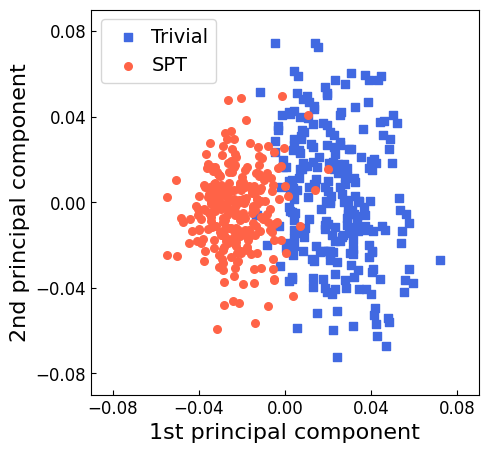

In [32]:
#PCA
from sklearn.datasets import load_digits
from sklearn.decomposition import KernelPCA

transformer = KernelPCA(n_components=2, kernel='precomputed')
X_transformed = transformer.fit_transform(G)
print(X_transformed)

num_data = 500
x_red = []
y_red = []
x_blue = []
y_blue = []
for i in range(num_data):
    if y[i]>0.5:
        x_red.append(X_transformed[i,0])
        y_red.append(X_transformed[i,1])
    else:
        x_blue.append(X_transformed[i,0])
        y_blue.append(X_transformed[i,1])
        

plt.figure(figsize=(5,5))
plt.xlim(-0.09,0.09)
plt.ylim(-0.09,0.09)
plt.rcParams['xtick.direction'] = 'in'
plt.rcParams['ytick.direction'] = 'in'
plt.xticks([-0.08, -0.04, 0, 0.04, 0.08], fontsize=12)
plt.yticks([-0.08, -0.04, 0, 0.04, 0.08], fontsize=12)
plt.xlabel("1st principal component", fontsize=16)
plt.ylabel("2nd principal component", fontsize=16)

plt.scatter(x_blue,y_blue, c="royalblue",s=30, marker="s", label="Trivial")
plt.scatter(x_red,y_red, c="tomato",s=30, marker="o", label="SPT")
plt.legend(fontsize=14, handletextpad=0.2)
plt.savefig(f"figs/pca_tesk_normalize.pdf", bbox_inches="tight", pad_inches=0.1)